In [29]:
import pandas as pd
import matplotlib.pyplot as plt


df=pd.read_csv("bank-full.csv", sep=";")

print("Dataset Shape:",df.shape)
display(df.head())

Dataset Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [30]:
print("No of columns in the dataset:", len(df.columns))
print("No of rows in the dataset:",len(df))

No of columns in the dataset: 17
No of rows in the dataset: 45211


In [31]:
print(df.columns)

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='str')


In [32]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB
None


### Understanding the Dataset

The Bank Marketing dataset contains 45,211 customer records and 17 columns.

- **Features (`X`):** Customer details and campaign information used to make predictions.
- **Target (`y`):** The `y` column indicates whether the customer subscribed to a term deposit (`yes` or `no`).
- **Data types:** Numerical columns contain numbers, while categorical columns contain labels such as occupation and marital status.

Our objective is to build a machine learning model that predicts whether a customer will subscribe to a term deposit.

In [33]:
display(df.describe())

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


## Column Descriptions

The dataset contains 17 columns: 16 input features and 1 target column.

| Column | Description |
|---|---|
| `age` | Age of the customer in years. |
| `job` | Customer's occupation, such as management, technician, or student. |
| `marital` | Marital status: married, single, or divorced. |
| `education` | Education level: primary, secondary, tertiary, or unknown. |
| `default` | Whether the customer has credit in default (`yes` or `no`). |
| `balance` | Average yearly account balance in euros. |
| `housing` | Whether the customer has a housing loan (`yes` or `no`). |
| `loan` | Whether the customer has a personal loan (`yes` or `no`). |
| `contact` | Communication method used for the last contact, such as cellular or telephone. |
| `day` | Day of the month when the customer was last contacted. |
| `month` | Month of the last contact. |
| `duration` | Duration of the last contact in seconds. |
| `campaign` | Number of contacts with the customer during the current campaign, including the last contact. |
| `pdays` | Number of days since the customer was contacted in a previous campaign. A value of `-1` means there was no previous contact recorded. |
| `previous` | Number of contacts made before the current campaign. |
| `poutcome` | Outcome of the previous marketing campaign, such as success, failure, or unknown. |
| `y` | **Target column:** whether the customer subscribed to a term deposit (`yes` or `no`). |

### Important Observation

The `y` column is what we want to predict. The `duration` column records the length of the last call, so we will exclude it from our main prediction model because its value is only known after the call has taken place.

The dataset also contains values such as `unknown` in some categorical columns and `-1` in `pdays`. These are meaningful data indicators and should not automatically be treated as ordinary missing values.

In [34]:
# No of missing values in the dataset
# missing values in the dataset are in the form of Unknown

print("No of missing values in each column:")
print(df.eq("unknown").sum())

print("No of missing values in the whole dataset:")
print(df.eq("unknown").sum().sum())


No of missing values in each column:
age              0
job            288
marital          0
education     1857
default          0
balance          0
housing          0
loan             0
contact      13020
day              0
month            0
duration         0
campaign         0
pdays            0
previous         0
poutcome     36959
y                0
dtype: int64
No of missing values in the whole dataset:
52124


In [35]:
print("No of Duplicate Rows in the dataset")
df.duplicated().sum()

No of Duplicate Rows in the dataset


np.int64(0)

y
no     39922
yes     5289
Name: count, dtype: int64


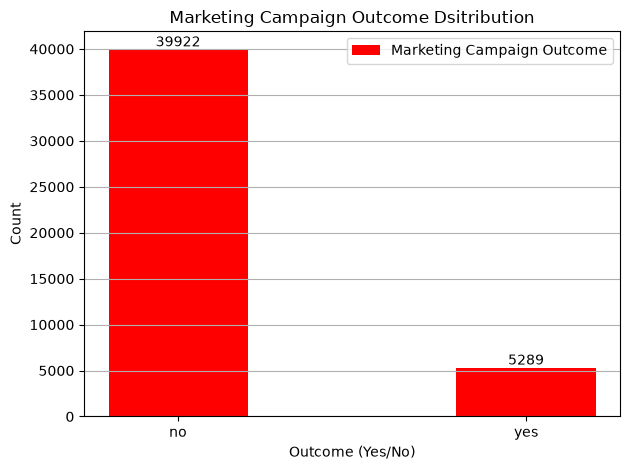

In [36]:
print(df["y"].value_counts())

yes_no=df["y"].value_counts()

x=yes_no.index
y=yes_no.values

plt.bar(x,y, color="red", width=0.4, label="Marketing Campaign Outcome")
plt.title("Marketing Campaign Outcome Dsitribution")
plt.xlabel("Outcome (Yes/No)")
plt.ylabel("Count")
plt.grid(True, axis="y")
plt.legend()
plt.tight_layout()
plt.bar_label(plt.gca().containers[0])
plt.show()

In [37]:
X=df.drop(columns=["y", "duration"])
y=df["y"]

# Convert categorical text columns into numeric columns
X=pd.get_dummies(X, drop_first=True, dtype=int)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.2, random_state=42, stratify=y)
# stratify=y preserves the proportion of yes and no outcomes in both sets.

print("Training Data:",X_train.shape)
print("Testing Data:",X_test.shape)


Training Data: (36168, 41)
Testing Data: (9043, 41)


In [38]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

logistic_regression=LogisticRegression(    max_iter=3000,
    class_weight="balanced")

# Train the model using training data
logistic_regression.fit(X_train, y_train)

# Predict outcomes for unseen test data
y_pred=logistic_regression.predict(X_test)

print("Accuracy of the model:",accuracy_score(y_test, y_pred))
print("Precision of the model:",precision_score(y_test, y_pred, pos_label="yes"))
print("Recall of the model:",recall_score(y_test, y_pred, pos_label="yes"))
print("F1 score of the model:",f1_score(y_test, y_pred, pos_label="yes"))
print("Classification Report:")
print(classification_report(y_test, y_pred))


Accuracy of the model: 0.7557226584098198
Precision of the model: 0.2669096800324018
Recall of the model: 0.6228733459357277
F1 score of the model: 0.3736886872696342
Classification Report:
              precision    recall  f1-score   support

          no       0.94      0.77      0.85      7985
         yes       0.27      0.62      0.37      1058

    accuracy                           0.76      9043
   macro avg       0.60      0.70      0.61      9043
weighted avg       0.86      0.76      0.79      9043



### Inference: Balanced Logistic Regression

- **Accuracy (0.7557):** The model correctly predicts approximately 75.57% of all test samples.
- **Precision (0.2669):** About 26.69% of customers predicted as `yes` actually subscribed.
- **Recall (0.6229):** The model identifies approximately 62.29% of actual subscribers.
- **F1-score (0.3737):** The balance between precision and recall for the `yes` class remains relatively low.

**Conclusion:** The balanced model identifies more actual subscribers but also produces more false-positive predictions. Its usefulness depends on balancing the need to find potential subscribers against the cost of contacting customers who do not subscribe.

In [40]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

decision_tree=DecisionTreeClassifier(class_weight="balanced", random_state=42)

decision_tree.fit(X_train, y_train)

y_pred_tree=decision_tree.predict(X_test)

print("Accuracy of the model:",accuracy_score(y_test,y_pred_tree))
print("Precision of the model:",precision_score(y_test, y_pred_tree, pos_label="yes"))
print("Recall of the model:",recall_score(y_test, y_pred_tree, pos_label="yes"))
print("F1 score of the model:",f1_score(y_test, y_pred_tree, pos_label="yes"))
print("Classification Report:")
print(classification_report(y_test, y_pred_tree))


Accuracy of the model: 0.8435253787459914
Precision of the model: 0.3202416918429003
Recall of the model: 0.3005671077504726
F1 score of the model: 0.3100926377376889
Classification Report:
              precision    recall  f1-score   support

          no       0.91      0.92      0.91      7985
         yes       0.32      0.30      0.31      1058

    accuracy                           0.84      9043
   macro avg       0.61      0.61      0.61      9043
weighted avg       0.84      0.84      0.84      9043



### Inference: Balanced Decision Tree

- **Accuracy (0.8435):** The model correctly classifies approximately 84.35% of all test samples.
- **Precision (0.3202):** About 32.02% of customers predicted as `yes` actually subscribed.
- **Recall (0.3006):** The model identifies approximately 30.06% of actual subscribers.
- **F1-score (0.3101):** The balance between precision and recall remains relatively low.

**Conclusion:** The Decision Tree achieves higher accuracy than the balanced Logistic Regression, but its recall and F1-score for subscribers are lower. Therefore, higher accuracy does not necessarily mean better identification of potential subscribers.

In [41]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

random_forest=RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1)
# n_jobs=-1 → use all available CPU cores.
random_forest.fit(X_train, y_train)

y_pred_rf=random_forest.predict(X_test)


print("Accuracy of the model:",accuracy_score(y_test,y_pred_rf))
print("Precision of the model:",precision_score(y_test, y_pred_rf, pos_label="yes"))
print("Recall of the model:",recall_score(y_test, y_pred_rf, pos_label="yes"))
print("F1 score of the model:",f1_score(y_test, y_pred_rf, pos_label="yes"))
print("Classification Report:")
print(classification_report(y_test, y_pred_rf))

Accuracy of the model: 0.8800176932433926
Precision of the model: 0.4842840512223516
Recall of the model: 0.3931947069943289
F1 score of the model: 0.43401147626499736
Classification Report:
              precision    recall  f1-score   support

          no       0.92      0.94      0.93      7985
         yes       0.48      0.39      0.43      1058

    accuracy                           0.88      9043
   macro avg       0.70      0.67      0.68      9043
weighted avg       0.87      0.88      0.87      9043



### Inference: Balanced Random Forest

- **Accuracy (0.8800):** The model correctly predicts approximately 88.00% of all test samples.
- **Precision (0.4843):** About 48.43% of customers predicted as `yes` actually subscribed.
- **Recall (0.3932):** The model identifies approximately 39.32% of actual subscribers.
- **F1-score (0.4340):** The model achieves a better balance between precision and recall than our previous models.

**Conclusion:** Random Forest performs better than the balanced Logistic Regression and Decision Tree in terms of F1-score for the `yes` class. It also has higher precision and accuracy than the balanced Logistic Regression, making it our current best-performing model.

In [42]:
from imblearn.ensemble._forest import BalancedRandomForestClassifier


print("Import successful!")

Import successful!


In [43]:
from imblearn.ensemble._forest import BalancedRandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

balanced_rf=BalancedRandomForestClassifier(random_state=42, n_jobs=-1)

balanced_rf.fit(X_train, y_train)

y_pred_brf=balanced_rf.predict(X_test)

print("Accuracy of the model:",accuracy_score(y_test,y_pred_brf))
print("Precision of the model:",precision_score(y_test, y_pred_brf, pos_label="yes"))
print("Recall of the model:",recall_score(y_test, y_pred_brf, pos_label="yes"))
print("F1 score of the model:",f1_score(y_test, y_pred_brf, pos_label="yes"))
print("Classification Report:")
print(classification_report(y_test, y_pred_brf))


Accuracy of the model: 0.8416454716355192
Precision of the model: 0.38370646766169153
Recall of the model: 0.5831758034026465
F1 score of the model: 0.4628657164291073
Classification Report:
              precision    recall  f1-score   support

          no       0.94      0.88      0.91      7985
         yes       0.38      0.58      0.46      1058

    accuracy                           0.84      9043
   macro avg       0.66      0.73      0.68      9043
weighted avg       0.88      0.84      0.86      9043



### Inference: Balanced Random Forest

- **Accuracy (0.8416):** The model correctly predicts approximately 84.16% of all test samples.
- **Precision (0.3837):** About 38.37% of customers predicted as `yes` actually subscribed.
- **Recall (0.5832):** The model identifies approximately 58.32% of actual subscribers.
- **F1-score (0.4629):** The model achieves a reasonable balance between precision and recall for the `yes` class.

**Conclusion:** Balanced Random Forest achieves the highest F1-score among the four models tested so far (0.4629). It identifies more actual subscribers than the Decision Tree and standard Random Forest, while maintaining better precision than balanced Logistic Regression. We will confirm the final best model after comparing all results.

Compare all four models

In [44]:
results = pd.DataFrame({
    "Model": [
        "Balanced Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Balanced Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_brf)
    ],
    "Precision": [
        precision_score(y_test, y_pred, pos_label="yes"),
        precision_score(y_test, y_pred_tree, pos_label="yes"),
        precision_score(y_test, y_pred_rf, pos_label="yes"),
        precision_score(y_test, y_pred_brf, pos_label="yes")
    ],
    "Recall": [
        recall_score(y_test, y_pred, pos_label="yes"),
        recall_score(y_test, y_pred_tree, pos_label="yes"),
        recall_score(y_test, y_pred_rf, pos_label="yes"),
        recall_score(y_test, y_pred_brf, pos_label="yes")
    ],
    "F1-score": [
        f1_score(y_test, y_pred, pos_label="yes"),
        f1_score(y_test, y_pred_tree, pos_label="yes"),
        f1_score(y_test, y_pred_rf, pos_label="yes"),
        f1_score(y_test, y_pred_brf, pos_label="yes")
    ]
})

display(results.round(4).sort_values("F1-score", ascending=False))

,Model,Accuracy,Precision,Recall,F1-score
3,Balanced Random Forest,0.8416,0.3837,0.5832,0.4629
2,Random Forest,0.8800,0.4843,0.3932,0.4340
0,Balanced Logistic Regression,0.7557,0.2669,0.6229,0.3737
1,Decision Tree,0.8435,0.3202,0.3006,0.3101


### Comparison of Machine Learning Models

Four classification models were evaluated using accuracy, precision, recall, and F1-score for the `yes` class.

- **Balanced Random Forest:** Achieved the highest F1-score (0.4629), providing the best balance between precision and recall among the tested models.
- **Random Forest:** Achieved the highest accuracy (0.8800) and precision (0.4843), but its recall was lower than that of Balanced Random Forest.
- **Balanced Logistic Regression:** Achieved the highest recall (0.6229), identifying the largest proportion of actual subscribers, but had lower precision.
- **Decision Tree:** Achieved an F1-score of 0.3101, the lowest among the four models.

**Conclusion:** Balanced Random Forest is the best model in this experiment when prioritizing F1-score. However, Random Forest may be preferable when precision and overall accuracy matter more, while Balanced Logistic Regression may be useful when identifying as many potential subscribers as possible is the priority. No single model is best for every objective.

## Final Project Conclusion

The Bank Marketing Response Prediction project aimed to predict whether a customer would subscribe to a bank's term deposit using customer and campaign information.

Four machine learning models were trained and evaluated: Balanced Logistic Regression, Decision Tree, Random Forest, and Balanced Random Forest. Their performance was compared using accuracy, precision, recall, and F1-score.

Balanced Random Forest achieved the highest F1-score of **0.4629** for the `yes` class, while Random Forest achieved the highest accuracy (**0.8800**) and precision (**0.4843**). Balanced Logistic Regression achieved the highest recall (**0.6229**), identifying the largest proportion of actual subscribers.

These results show that model selection depends on the business objective. F1-score is a useful primary metric when balancing precision and recall, while recall is important when identifying as many potential subscribers as possible.

The project demonstrates how machine learning can support marketing decisions. However, predictions are not guarantees, and the models' performance should be improved and validated before real-world deployment.

In [46]:
import joblib

joblib.dump(logistic_regression, "balanced_logistic_regression.pkl")
joblib.dump(decision_tree, "decision_tree.pkl")
joblib.dump(random_forest, "random_forest.pkl")
joblib.dump(balanced_rf, "balanced_random_forest.pkl")
joblib.dump(scaler, "scaler.pkl")

print("All four models saved successfully!")

All four models saved successfully!


In [47]:
import joblib

joblib.dump(X.columns.tolist(), "model_columns.pkl")

print("Training feature columns saved!")

Training feature columns saved!
